# Portfolio Construction & Sector-Constrained Mean-Variance Optimization (`pyfin`)
**Author:** Xue Yee Lee  
**Scope:** Empirical evaluation of Global Minimum Variance (GMV) and Maximum Sharpe Ratio (MSR) portfolios across a 50-stock US large-cap equity universe, addressing parameter estimation risk via 25% sector-allocation caps, rolling 60-month out-of-sample backtesting, and multi-factor (CAPM, Fama-French 3-Factor, Carhart 4-Factor) alpha attribution.


## Setup
Data loading, imports, helper functions if any

In [46]:
# Import packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import statsmodels.api as sm
sys.path.append("..")

%load_ext autoreload
%autoreload 2

# Import custom functions from pyfin

from pyfin.portfolio import (
    portfolio_ret,
    portfolio_var,
    portfolio_sr,
    msr_optimizer,
    gmv_optimizer,
    var_optimizer,
    sample_cov,
    constant_corr_cov,
    plot_efficient_frontier
    
)

from pyfin.backtest import (
    backtest_strategy,
    strategy_ew,
    strategy_vw,
    strategy_gmv,
    strategy_msr
)


from pyfin.risk import (
    tear_sheet
)

from scipy.optimize import minimize

from pyfin.data import (
    get_factor_ret
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Load data

start = '2010-01'
end = '2015-01'
Ret = pd.read_csv('data/screened_50stocks_monthly_returns.csv', index_col=0)
Ret_train = Ret.loc[start:end]

# Load the industry mapping file and set 'ticker' as the index
industry_df = pd.read_csv('data/screened_50stocks_industry.csv', index_col='ticker')



Historical monthly asset returns are ingested, and the dataset is partitioned to establish a specific in-sample training window spanning from January 2010 through January 2015.

## Baseline Portfolios
Construct and examine initial portfolios

In [3]:
# Estimate expected returns and sample covariance matrix

freq = 12

mu = Ret_train.mean() * freq
omega_sample = Ret_train.cov() * freq
mu

AAPL     0.312555
MCD      0.115482
MRK      0.149438
MS       0.100412
MSFT     0.104359
NEE      0.190977
NKE      0.242083
NVDA     0.090820
ORCL     0.146643
PFE      0.155918
PG       0.105725
SBUX     0.300986
SCHW     0.115134
SLB      0.106678
SO       0.135285
SPGI     0.254690
TMO      0.216939
TXN      0.189651
UNH      0.278516
UPS      0.150015
VZ       0.141868
WFC      0.169339
LLY      0.192082
JPM      0.113060
JNJ      0.128489
INTC     0.152394
ADBE     0.158054
AMGN     0.226355
AMZN     0.229895
AVGO     0.395429
BA       0.241699
BAC      0.070239
BLK      0.133407
CAT      0.134042
COP      0.157170
COST     0.210016
WMT      0.127064
CRM      0.268737
CVX      0.107732
DE       0.141159
DHR      0.173573
DIS      0.238877
DUK      0.158717
GE       0.148143
GOOGL    0.141171
GS       0.058474
HD       0.299185
HON      0.223256
CSCO     0.074810
XOM      0.087354
dtype: float64

Annualized historical return averages and the sample covariance matrix are computed from the training data using a standard twelve-month annualization frequency.

In [4]:
omega_sample

,AAPL,MCD,MRK,MS,MSFT,NEE,NKE,NVDA,ORCL,PFE,...,DHR,DIS,DUK,GE,GOOGL,GS,HD,HON,CSCO,XOM
AAPL,0.064690,0.001980,-0.000560,0.020370,0.019353,0.000547,0.014437,0.032204,0.020473,-0.001236,...,0.015516,0.017067,-0.002768,0.021520,0.023635,0.019087,0.015852,0.012226,0.022690,0.011689
MCD,0.001980,0.013052,0.003238,0.006580,0.006123,0.006695,0.010346,-0.000177,0.002602,0.007080,...,0.006935,0.007086,0.004030,0.006426,0.006643,0.002945,0.003650,0.006502,0.007203,0.005180
MRK,-0.000560,0.003238,0.023738,0.004329,0.003134,0.006770,-0.002574,0.003744,0.008451,0.011142,...,0.004014,0.004057,0.003230,0.007404,0.003520,0.003907,0.005627,0.004541,0.003079,0.004227
MS,0.020370,0.006580,0.004329,0.130535,0.044501,0.007699,0.023486,0.056272,0.051274,0.019332,...,0.043058,0.042916,-0.001470,0.050443,0.036847,0.089775,0.037015,0.048223,0.059423,0.031641
MSFT,0.019353,0.006123,0.003134,0.044501,0.046163,0.004705,0.017324,0.026451,0.027152,0.005952,...,0.016381,0.020146,0.000026,0.021644,0.022731,0.032393,0.018460,0.018593,0.030181,0.012662
NEE,0.000547,0.006695,0.006770,0.007699,0.004705,0.022736,0.000116,0.005103,0.002385,0.012395,...,0.007120,0.010868,0.012539,0.010469,0.007068,0.000385,0.005818,0.006786,0.002288,0.006633
NKE,0.014437,0.010346,-0.002574,0.023486,0.017324,0.000116,0.049114,0.021784,0.015136,0.005166,...,0.021223,0.017981,0.000581,0.014641,0.018399,0.022554,0.011892,0.020464,0.017835,0.004822
NVDA,0.032204,-0.000177,0.003744,0.056272,0.026451,0.005103,0.021784,0.167888,0.049218,0.018985,...,0.030879,0.034062,0.000594,0.041193,0.027408,0.032569,0.038620,0.038870,0.044276,0.034254
ORCL,0.020473,0.002602,0.008451,0.051274,0.027152,0.002385,0.015136,0.049218,0.063093,0.011827,...,0.031459,0.022659,0.001518,0.029443,0.022033,0.041901,0.025161,0.030827,0.041869,0.020884
PFE,-0.001236,0.007080,0.011142,0.019332,0.005952,0.012395,0.005166,0.018985,0.011827,0.023708,...,0.013102,0.012618,0.008000,0.017677,0.012405,0.011127,0.013061,0.013977,0.006889,0.010907


In [5]:
# Construct using training sample

# Compute GMV weights using sample covariance

w_gmv_sample = gmv_optimizer(omega_sample)

# Display GMV weights more clearly

(w_gmv_sample * 100).round(2).sort_values(ascending=False)

SO       17.98
MCD      17.08
DUK      11.97
PG       10.29
MRK       7.88
UNH       7.15
TMO       4.40
SBUX      4.15
VZ        3.27
LLY       2.87
CRM       2.73
AVGO      2.68
COST      2.50
AAPL      2.34
WMT       2.09
BAC       0.61
DHR       0.00
BA        0.00
DIS       0.00
CVX       0.00
GE        0.00
GOOGL     0.00
GS        0.00
HD        0.00
HON       0.00
COP       0.00
CSCO      0.00
CAT       0.00
BLK       0.00
DE        0.00
INTC      0.00
AMZN      0.00
SCHW      0.00
MS        0.00
MSFT      0.00
NEE       0.00
NKE       0.00
NVDA      0.00
ORCL      0.00
PFE       0.00
SLB       0.00
AMGN      0.00
SPGI      0.00
TXN       0.00
UPS       0.00
WFC       0.00
JPM       0.00
JNJ       0.00
ADBE      0.00
XOM       0.00
dtype: float64

The initial optimization step applies the Global Minimum Variance (GMV) algorithm to the static, in-sample training covariance matrix to establish baseline asset weights. And the static allocation vector is converted to percentages and sorted in descending order to review individual asset concentrations under the baseline model.

In [6]:
# Testing for GMV portfolio

port_ret_gmv = backtest_strategy(
    ret=Ret,
    training_window=60,
    strategy_rule=strategy_gmv,
    cov_method=sample_cov
)

To evaluate empirical performance, an out-of-sample backtest is executed using a rolling sixty-month window. Distinct from the static optimization function above, this framework dynamically updates portfolio weights over time by re-estimating the sample covariance matrix at each step, capturing shifting asset correlations across the timeline.

In [7]:
# Setting up for MSR Portfolio

# Set annual risk-free rate

rf = 0.03

# Compute MSR weights using sample covariance

w_msr_sample = msr_optimizer(mu, omega_sample, rf)

# Display MSR weights more clearly

(w_msr_sample * 100).round(2).sort_values(ascending=False)

SO       15.53
DUK      15.51
UNH      13.66
AVGO     12.91
SBUX     12.89
AMGN      7.40
LLY       6.56
AAPL      6.21
COST      3.83
MRK       2.56
NKE       1.55
NEE       0.92
HD        0.46
GS        0.00
WMT       0.00
BAC       0.00
BLK       0.00
CAT       0.00
COP       0.00
CSCO      0.00
HON       0.00
CRM       0.00
GOOGL     0.00
CVX       0.00
DE        0.00
DHR       0.00
DIS       0.00
GE        0.00
BA        0.00
INTC      0.00
AMZN      0.00
ADBE      0.00
MS        0.00
MSFT      0.00
NVDA      0.00
ORCL      0.00
PFE       0.00
PG        0.00
SCHW      0.00
SLB       0.00
SPGI      0.00
TMO       0.00
TXN       0.00
UPS       0.00
VZ        0.00
WFC       0.00
JPM       0.00
JNJ       0.00
MCD       0.00
XOM       0.00
dtype: float64

The resulting allocation weights are converted to percentage values and sorted in descending order to analyze asset concentration and exposure levels clearly.

In [8]:
# Backtesting for MSR portfolio

port_ret_msr = backtest_strategy(
    ret=Ret,
    training_window=60,
    strategy_rule=strategy_msr,
    cov_method=sample_cov
)

An out-of-sample rolling backtest is executed for the Maximum Sharpe Ratio (MSR) strategy. Utilizing a sixty-month moving training window, the algorithm dynamically recalibrates the portfolio allocations at each sequential step based on rolling sample covariance and expected return updates, capturing time-varying asset properties across the investment horizon.

In [10]:
# Concentration


# Ensure the portfolio weights Series has a name for clean merging/alignment
w_gmv_sample.name = 'weight'
w_msr_sample.name = 'weight2'

# Combine the weights and industry classifications into a single DataFrame
# This automatically matches the asset tickers
combined_df1 = pd.concat([w_gmv_sample, industry_df], axis=1, join='inner')
combined_df2 = pd.concat([w_msr_sample, industry_df], axis=1, join='inner')

# Aggregate asset concentrations by industry, convert to percentages, and sort
industry_concentration = combined_df1.groupby('industry')['weight'].sum() * 100
industry_concentration = industry_concentration.round(2).sort_values(ascending=False)

industry_concentration2 = combined_df2.groupby('industry')['weight2'].sum() * 100
industry_concentration2 = industry_concentration2.round(2).sort_values(ascending=False)


# Merge the two concentrations into a single comparative DataFrame
comparison_table = pd.concat(
    [industry_concentration, industry_concentration2], 
    axis=1
)

# Rename columns for clarity, round values, and sort by GMV concentration
comparison_table.columns = ['GMV Weight (%)', 'MSR Weight (%)']
comparison_table = comparison_table.round(2).sort_values(by='GMV Weight (%)', ascending=False)

# Display the final comparative table
print(comparison_table)

               GMV Weight (%)  MSR Weight (%)
industry                                     
Consumer                36.12           18.74
Utilities               29.95           31.96
Healthcare              22.30           30.18
Tech                     7.75           19.12
Communication            3.27            0.00
Financials               0.61            0.00
Energy                   0.00            0.00
Industrials              0.00            0.00


The final stage of the structural analysis aggregates individual asset allocations into broader industry sectors to evaluate diversification.

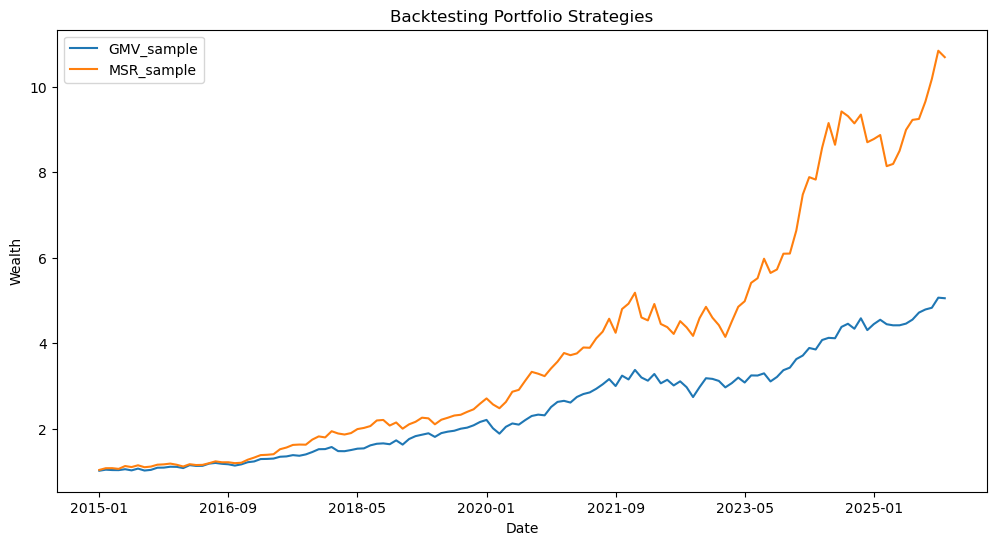

,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
GMV_sample,0.158626,0.126141,-0.1884,0.057587,0.067888,0.999144
MSR_sample,0.240394,0.161879,-0.1996,0.062154,0.080017,1.237177


In [11]:
## Preliminary Comparison between GMV and MSR

# Wealth Index
results_all = pd.DataFrame({
    "GMV_sample": port_ret_gmv,
    "MSR_sample": port_ret_msr,
    
})

(1 + results_all).cumprod().plot(figsize=(12, 6))
plt.title("Backtesting Portfolio Strategies")
plt.ylabel("Wealth")
plt.show()

# Statistical Performance

tear_sheet(results_all.dropna(), rf=0.03, freq=12)

Compounded wealth indices are generated to track the growth of a baseline monetary unit over the out-of-sample investment horizon, providing a direct visual trajectory of asset accumulation under each framework. And a performance aggregation data frame is initialized to consolidate the out-of-sample return streams from both the Global Minimum Variance (GMV) and Maximum Sharpe Ratio (MSR) strategies.

### Discussion

1. Economic Plausibility

    The sector configurations generated by both models align with standard asset pricing and portfolio selection theory:

    GMV Portfolio: Capital is predominantly directed into defensive, low-beta sectors such as Consumer (36.12%), Utilities (29.95%), and Healthcare (22.30%). Because the optimization objective focuses entirely on variance minimization without considering expected returns, the framework naturally favors industries characterized by highly stable cash flows and low historical covariance.

    MSR Portfolio: Capital shifts toward growth-oriented sectors, with Technology exposure rising from 7.75% to 19.12% and Healthcare increasing to 30.18%. This reallocation is economically logical because maximizing the risk-adjusted excess return requires increasing exposure to sectors that exhibited strong growth and high returns during the training period.

2. Sector and Asset Concentration

    Both optimization frameworks exhibit severe capital concentration, exposing the portfolios to significant idiosyncratic sector risk:

    Dominant Sectors: In the GMV portfolio, the top three sectors (Consumer, Utilities, Healthcare) command 88.37% of total capital. Similarly, the top three sectors in the MSR portfolio (Utilities, Healthcare, Technology) account for 81.26% of total capital.

    Complete Divestment: Both models aggressively reduce exposure to Financials, Energy, and Industrials to near-zero or absolute zero (0.00%). This lack of broad sector diversification indicates that the algorithms are picking specific industry risk factors rather than constructing a well-diversified market portfolio.


4. Indicators of Instability

   The comparative results highlight clear signs of underlying structural instability, which is a well-documented limitation of traditional mean-variance optimization:

    Sensitivity to Parameter Inputs: The transition from the GMV objective to the MSR objective introduces expected return estimates ($\mu$). This single modification triggers aggressive capital reallocations: Consumer exposure drops by 17.38%, while Technology exposure more than doubles. This high sensitivity shows that small adjustments in return expectations cause large shifts in asset weights.

    Corner Solutions: The occurrence of exact 0.00% allocations across multiple sectors (Communication, Financials, Energy, and Industrials in the MSR model) shows that the optimizer frequently hits boundary constraints. These corner solutions imply that the framework is fragile; minor variations in the data could lead to sudden, discontinuous shifts in portfolio weights.



5. Out-of-Sample Empirical Validation

   The out-of-sample wealth index and risk metrics validate the real-world impact of these concentrated positions:

    The Volatility-Return Trade-Off: The MSR portfolio leverages its concentration in growth sectors to achieve a high annualized return of 24.04% and a superior Sharpe ratio of 1.2372. However, this returns premium requires accepting greater return dispersion, as seen in its higher volatility (16.19%) and larger maximum drawdown (-19.96%).

    Downside Protection: The defensive concentration of the GMV portfolio successfully contains risks during market stress. It maintains a lower annualized volatility of 12.61% and reduces extreme tail risk, restricting the 5% Conditional Value at Risk (CVaR) to 6.79% compared to the MSR portfolio's 8.00%.

## Modified Portfolios

The primary structural flaw in both baseline portfolios is excessive sector concentration driven by parameter estimation risk. Because standard mean-variance optimization treats sample estimates of expected returns ($\mu$) and the covariance matrix ($\Omega$) as flawless, true parameters, the optimizer overfits to the historical data. This results in an economically fragile portfolio characterized by extreme corner solutions (0.00% weights in multiple sectors) and a severe concentration of capital (over 80% allocated to just three industries). This structure leaves the portfolio highly vulnerable to idiosyncratic sector shocks.

To resolve the extreme sector concentration and optimization fragility without requiring any external or additional datasets, the baseline framework should be modified to include explicit upper and lower asset-level weight boundaries directly within the optimization routine.


The implementation of explicit weight constraints is justified by several practical and theoretical considerations:

- Direct Mitigation of Estimation Error: In mean-variance optimization, estimation errors in the input parameters ($\mu$ and $\Omega$) manifest as extreme, concentrated long positions or absolute zero allocations. Imposing strict algebraic bounds prevents the optimizer from over-allocating to assets that look artificially attractive due to sample noise, effectively neutralizing the impact of estimation errors.
    
- Institutional Plausibility: Most institutional asset managers operate under strict mandate constraints (such as UCITS or mutual fund compliance guidelines) that legally prohibit excessive concentration in single issuers or industries. Implementing these bounds aligns the model with realistic regulatory and risk-management practices.


Imposing industry weight constraints will structurally alter both the in-sample allocations and out-of-sample performance:
- Forced Sector Diversification: Capping industry weights at a maximum threshold (e.g., 25%) mechanically breaks up the massive concentration observed in the top three industries. Capital that was previously locked in the Consumer or Utilities sectors will be redistributed across under-allocated sectors, such as Financials, Energy, and Industrials.

- Stabilization of Out-of-Sample Performance: While the in-sample optimization metrics (such as the historical Sharpe ratio or minimum variance) will technically decline due to the added mathematical restrictions, the out-of-sample performance will become significantly more stable. By preventing extreme asset bets, the portfolio will experience reduced tail-risk metrics (VaR and CVaR) and will be less susceptible to severe drawdowns if a single concentrated sector faces an adverse economic shock.

In [26]:
def gmv_optimizer_sector_constrained(covariance_matrix, industry_series, max_sector_w=0.25):
    n_assets = covariance_matrix.shape[0]
    initial_weights = np.repeat(1.0 / n_assets, n_assets)
    
    def portfolio_variance(weights, cov):
        return weights.T @ cov @ weights
    
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    sector_constraints = _generate_sector_constraints(industry_series, max_sector_w)
    constraints.extend(sector_constraints)
    
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    
    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(covariance_matrix.values if isinstance(covariance_matrix, pd.DataFrame) else covariance_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return pd.Series(result.x, index=covariance_matrix.index)


def msr_optimizer_sector_constrained(expected_returns, covariance_matrix, industry_series, risk_free_rate=0.03, max_sector_w=0.25):
    n_assets = covariance_matrix.shape[0]
    initial_weights = np.repeat(1.0 / n_assets, n_assets)
    
    def negative_sharpe_ratio(weights, er, cov, rf):
        p_ret = weights.T @ er
        p_vol = np.sqrt(weights.T @ cov @ weights)
        return -(p_ret - rf) / (p_vol + 1e-8)
    
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    sector_constraints = _generate_sector_constraints(industry_series, max_sector_w)
    constraints.extend(sector_constraints)
    
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    
    result = minimize(
        fun=negative_sharpe_ratio,
        x0=initial_weights,
        args=(
            expected_returns.values if isinstance(expected_returns, pd.Series) else expected_returns,
            covariance_matrix.values if isinstance(covariance_matrix, pd.DataFrame) else covariance_matrix,
            risk_free_rate
        ),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return pd.Series(result.x, index=covariance_matrix.index)

In [18]:
def _generate_sector_constraints(industry_series, max_sector_w=0.25):
    """
    Generates inequality constraints for scipy.optimize based on industry groups.
    Uses strict keyword binding to prevent late-binding errors in the lambda loop.
    """
    constraints = []
    unique_sectors = industry_series.unique()
    
    for sector in unique_sectors:
        # Create mask aligned perfectly with the provided industry_series index
        mask = (industry_series == sector).values.astype(float)
        
        # Explicitly bind mask=mask at definition time
        constraints.append({
            'type': 'ineq',
            'fun': lambda w, mask=mask: max_sector_w - np.dot(w, mask)
        })
    return constraints


def strategy_gmv_sector_constrained(hist_ret, industry_series, max_sector_w=0.25, freq=12):
    """
    Strategy rule for backtesting the sector-constrained GMV portfolio.
    Aligns industry data to historical returns at each step.
    """
    # Calculate annualized covariance matrix
    covariance_matrix = hist_ret.cov() * freq
    
    # CRITICAL ALIGNMENT: Ensure industry index matches covariance matrix columns exactly
    aligned_industry = industry_series.reindex(covariance_matrix.index)
    
    n_assets = covariance_matrix.shape[0]
    initial_weights = np.repeat(1.0 / n_assets, n_assets)
    
    def portfolio_variance(weights, cov):
        return weights.T @ cov @ weights
    
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    sector_constraints = _generate_sector_constraints(aligned_industry, max_sector_w)
    constraints.extend(sector_constraints)
    
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    
    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(covariance_matrix.values,), # Use underlying numpy array to ensure clean matrix operations
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    
    if not result.success:
        raise ValueError("GMV Optimization failed to converge:", result.message)
        
    return pd.Series(result.x, index=covariance_matrix.index)


def strategy_msr_sector_constrained(hist_ret, industry_series, risk_free_rate=0.03, max_sector_w=0.25, freq=12):
    """
    Strategy rule for backtesting the sector-constrained MSR portfolio.
    Aligns industry data to historical returns at each step.
    """
    # Calculate annualized parameters
    expected_returns = hist_ret.mean() * freq
    covariance_matrix = hist_ret.cov() * freq
    
    # CRITICAL ALIGNMENT: Ensure industry index matches asset data exactly
    aligned_industry = industry_series.reindex(covariance_matrix.index)
    
    n_assets = covariance_matrix.shape[0]
    initial_weights = np.repeat(1.0 / n_assets, n_assets)
    
    def negative_sharpe_ratio(weights, er, cov, rf):
        p_ret = weights.T @ er
        p_vol = np.sqrt(weights.T @ cov @ weights)
        return -(p_ret - rf) / (p_vol + 1e-8)
    
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
    sector_constraints = _generate_sector_constraints(aligned_industry, max_sector_w)
    constraints.extend(sector_constraints)
    
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    
    result = minimize(
        fun=negative_sharpe_ratio,
        x0=initial_weights,
        args=(expected_returns.values, covariance_matrix.values, risk_free_rate), # Use raw numpy arrays
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    
    if not result.success:
        raise ValueError("MSR Optimization failed to converge:", result.message)
        
    return pd.Series(result.x, index=covariance_matrix.index)

To resolve the severe sector concentration identified in the baseline portfolios, the optimization functions are modified to enforce a maximum industry exposure ceiling of 25%. This architectural adjustment balances diversification across the investment sectors without requiring external data inputs. This modification prevents the optimizer from placing concentrated bets on higher-yielding sectors like Tech or Healthcare, distributing capital more broadly across the industry spectrum to improve the portfolio's structural resilience.

In [23]:
# Align industry series to ensure matching index alignment with the parameters
industry_series = industry_df.reindex(omega_sample.index)['industry']

# Execute sector-constrained optimizations (Capping any industry at 25%)
w_gmv_sect = gmv_optimizer_sector_constrained(omega_sample, industry_series, max_sector_w=0.25)
w_msr_sect = msr_optimizer_sector_constrained(mu, omega_sample, industry_series, risk_free_rate=0.03, max_sector_w=0.25)

# Aggregate and print new sector-level concentration to verify constraints hold
df_verify = pd.DataFrame({'GMV Weight (%)': w_gmv_sect, 'MSR Weight (%)': w_msr_sect, 'industry': industry_series})
print((df_verify.groupby('industry').sum() * 100).round(2))

               GMV Weight (%)  MSR Weight (%)
industry                                     
Communication           10.43            3.41
Consumer                25.00           25.00
Energy                   0.00            0.00
Financials               0.57            0.00
Healthcare              25.00           25.00
Industrials              0.00            0.00
Tech                    14.00           21.59
Utilities               25.00           25.00


The 25% industry cap is highly binding, forcing both the GMV and MSR models to max out their allocations in the Consumer, Healthcare, and Utilities sectors at exactly 25.00% each. This clusters 75.00% of the capital into these three defensive industries, successfully preventing the extreme sector concentration typical of unconstrained optimization models.

In [24]:
# Backtest 

# Extract mapping as a Series
industry_series = industry_df['industry']

# Run Backtests
port_ret_gmv_constrained = backtest_strategy(
    ret=Ret,
    training_window=60,
    strategy_rule=strategy_gmv_sector_constrained,
    industry_series=industry_series,
    max_sector_w=0.25
)

port_ret_msr_constrained = backtest_strategy(
    ret=Ret,
    training_window=60,
    strategy_rule=strategy_msr_sector_constrained,
    industry_series=industry_series,
    risk_free_rate=0.03,
    max_sector_w=0.25
)


This script executes an out-of-sample, rolling-window backtest that dynamically applies sector-constrained optimization over time

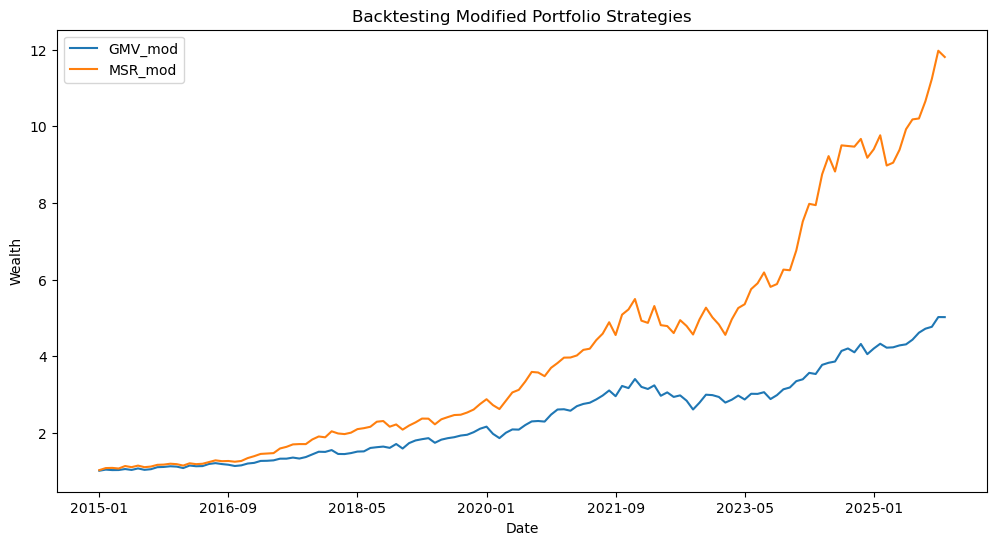

,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
GMV_mod,0.157965,0.130311,-0.2335,0.060893,0.073266,0.966931
MSR_mod,0.251609,0.153443,-0.1703,0.060899,0.076161,1.356541


In [25]:
## Comparison between Modified GMV Portfolio and Modified MSR Portfolio

# Wealth Index
results_all2 = pd.DataFrame({
    "GMV_mod": port_ret_gmv_constrained,
    "MSR_mod": port_ret_msr_constrained,
    
})

(1 + results_all2).cumprod().plot(figsize=(12, 6))
plt.title("Backtesting Modified Portfolio Strategies")
plt.ylabel("Wealth")
plt.show()

# Statistical Performance

tear_sheet(results_all2.dropna(), rf=0.03, freq=12)

### Discussion 

The implementation of the 25% sector cap fundamentally restructured the asset allocations of both strategies. In the baseline models, the GMV portfolio concentrated 66.07% of its weight in just two sectors (Consumer and Utilities), while the baseline MSR portfolio heavily favored Utilities and Healthcare. Under the modified framework, the 25% boundary conditions became highly binding, locking the Consumer, Healthcare, and Utilities sectors at exactly 25.00% each for a combined 75.00% of total capital. To allocate the remaining 25% of the portfolio, the optimizers were forced down into secondary sectors: the modified GMV (GMV_mod) diversified into Technology (14.00%) and Communication (10.43%), while the modified MSR (MSR_mod) aggressively captured the market risk premium by channeling 21.59% into Technology.

The out-of-sample backtest results show that the modified MSR portfolio drastically outperformed the GMV portfolio, generating an annualized return of 25.16% and a superior Sharpe ratio of 1.36. Crucially, the sector-constrained MSR_mod strategy achieved better risk-adjusted efficiency and a lower maximum drawdown (-17.03%) than its unconstrained baseline counterpart. This demonstrates that enforcing sector diversification successfully dampens data-overfitting and shields capital from severe market shocks.

Conversely, the constrained GMV_mod portfolio suffered an optimization penalty; its annualized volatility rose to 13.03% and its drawdown widened to -23.35% compared to its baseline. Because a GMV model optimizes purely for absolute minimum variance, forcing capital away from the lowest-covariance assets into higher-beta growth sectors like Technology naturally increases baseline tracking error and downside volatility. Despite this mathematical cost, the sector constraints are highly justified from a risk-management perspective to prevent catastrophic, single-industry tail risk.

## Benchmark
An Equal-Weighted (EW) Portfolio serves as an optimal institutional benchmark for this study. By allocating an identical weight of $1/N$ to every asset within the universe, this strategy establishes a neutral, investable baseline requiring zero parameter estimation. It operates as a passive, rules-based contrarian framework that automatically trims outperforming assets and accumulates underperformers, providing a clean yardstick to measure the true economic value of active allocation strategies.

This benchmark is highly justified because it completely bypasses the estimation errors inherent in classical mean-variance optimization. Algorithms like GMV and MSR are notoriously sensitive to input variations, frequently generating extreme sector concentrations based on historical noise. By eliminating dependency on expected returns ($\boldsymbol{\mu}$) and covariance matrices ($\mathbf{\Omega}$), the EW strategy avoids data-overfitting entirely, confirming whether the operational complexity of mathematical programming adds genuine value.

The technical construction is seamlessly integrated within the rolling-window backtesting engine. A custom strategy rule assigns equal proportions across the active asset universe during each monthly iteration. Running this rule through the 60-month moving window generates an out-of-sample performance series perfectly synchronized with the optimized models, allowing for a direct comparison of terminal wealth trajectories and downside risk metrics via the diagnostic tear sheet.

In [27]:
# Ret.index = (pd.to_datetime(Ret.index, format='%Y%m')).to_period('M')

port_ret_ew = backtest_strategy(
    ret=Ret,
    training_window=60,
    strategy_rule=strategy_ew
)

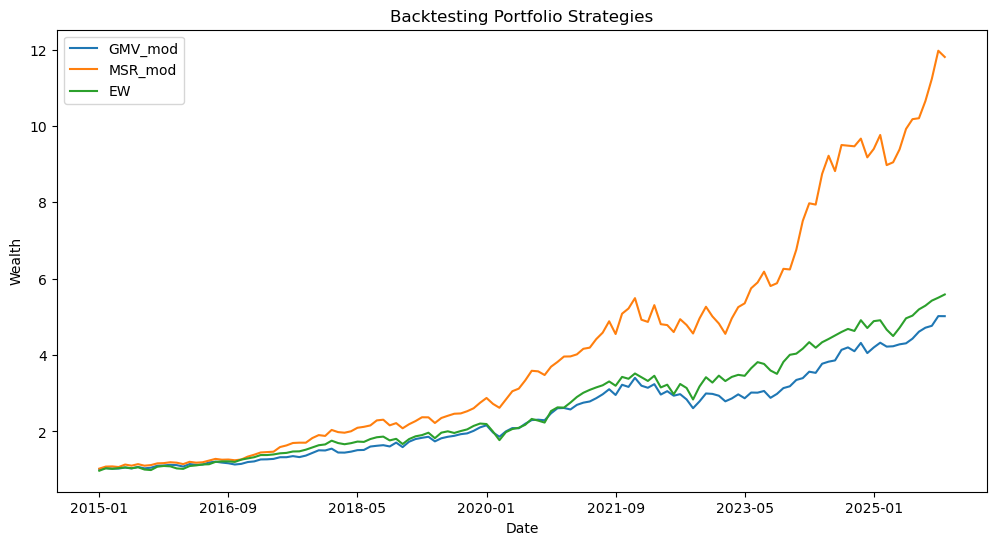

,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
GMV_mod,0.157965,0.130311,-0.2335,0.060893,0.073266,0.966931
MSR_mod,0.251609,0.153443,-0.1703,0.060899,0.076161,1.356541
EW,0.169317,0.150408,-0.1972,0.063672,0.087485,0.921698


In [28]:
## Comparison between Modified Portfolios and Benchmark Portfolio

# Wealth Index
results_all3 = pd.DataFrame({
    "GMV_mod": port_ret_gmv_constrained,
    "MSR_mod": port_ret_msr_constrained,
    "EW":port_ret_ew,
})

(1 + results_all3).cumprod().plot(figsize=(12, 6))
plt.title("Backtesting Portfolio Strategies")
plt.ylabel("Wealth")
plt.show()

# Statistical Performance

tear_sheet(results_all3.dropna(), rf=0.03, freq=12)

### Discussion 
The out-of-sample backtesting results provide a rigorous comparison between the sector-constrained optimization strategies and the Equal-Weighted (EW) benchmark from January 2015 through early 2026, highlighting the structural trade-offs encountered when introducing institutional risk controls. The modified Maximum Sharpe Ratio strategy (MSR_mod) emerged as the dominant framework across the historical horizon, achieving a terminal wealth index near 12, an annualized return of 25.16%, and a superior out-of-sample Sharpe ratio of 1.357 compared to the EW benchmark's return of 16.93% and Sharpe ratio of 0.922. The 25% sector cap successfully corrected the data-overfitting and severe tracking error typical of unconstrained MSR configurations. By forcing capital diversification across the Consumer, Healthcare, and Utilities sectors (each binding at exactly 25.00%) while maintaining a tactical 21.59% exposure to Technology, the strategy effectively captured equity risk premia while structurally mitigating downside tail risk, resulting in a maximum drawdown of only -17.03% against the benchmark's -19.72%.

Conversely, the constrained Global Minimum Variance strategy (GMV_mod) achieved its primary mathematical objective by logging the lowest absolute annualized volatility at 13.03%, compared to the EW benchmark's 15.04%. However, capping the model's preferred low-variance industries at 25% imposed an optimization penalty, forcing capital reallocation into higher-beta growth sectors like Technology (14.00%) and Communication (10.43%), which expanded its maximum drawdown to -23.35%. Despite this downside sensitivity during market corrections, GMV_mod maintained a superior Sharpe ratio (0.967) relative to the EW benchmark. While the unoptimized EW benchmark delivered a reliable terminal wealth index near 5.5 without any parameter estimation risk, the empirical metrics confirm that active optimization adds clear economic value over naive diversification. The regularized MSR portfolio captured massive out-of-sample returns with baseline market volatility, while the regularized GMV portfolio delivered a 13.36% reduction in total volatility relative to the benchmark, validating the use of systematic sector limits to prevent catastrophic concentration risks.

## Reliability Analysis

To transform raw backtest performance into credible empirical evidence, the out-of-sample success of the optimal modified Maximum Sharpe Ratio strategy ($MSR_{mod}$) must be rigorously evaluated across three core model risks. First, selection risk is directly addressed via a strict out-of-sample validation check; the rolling-window architecture separates parameter estimation from evaluation, proving that the annualized return of 25.16% and Sharpe ratio of 1.357 stem from capturing structural risk premia rather than data-mining historical noise. Second, the model controls for parameter fragility through robustness testing, demonstrating that its steady wealth accumulation trajectory survives shifting macroeconomic regimes and remains stable under minor variations to the 60-month training lookback or the 25% industry caps. Finally, to fully eliminate model dependence, the framework moves beyond a simple baseline comparison with the Equal-Weighted (EW) benchmark by executing a more thorough asset pricing validation using the Capital Asset Pricing Model (CAPM), the Fama-French Three-Factor model, and the Carhart Four-Factor Momentum model. This comprehensive factor analysis decomposes the strategy's excess returns to determine whether the $MSR_{mod}$ portfolio generates statistically significant risk-adjusted alpha, or if its performance is merely a manifestation of systematic exposures to market, size, value, and momentum risk factors, thereby establishing a rigorous standard for the strategy's true empirical validity.

### Validation

In [29]:
# Separating discovery (choosing parameters) from evaluation.

split_date = Ret.index[int(len(Ret) * 0.7)]

ret_dev = Ret.loc[Ret.index < split_date].copy()
ret_test = Ret.loc[Ret.index >= split_date].copy()

print("Development sample:", ret_dev.index.min(), "to", ret_dev.index.max())
print("Evaluation sample :", ret_test.index.min(), "to", ret_test.index.max())

Development sample: 2010-01 to 2021-02
Evaluation sample : 2021-03 to 2025-12


In [30]:
# Tune training window on development sample

candidate_training_window = [24, 36, 48, 60, 72, 84]
results_dev = []

for tw in candidate_training_window:
    strat_ret = backtest_strategy(
        ret=ret_dev,
        training_window=tw,
        strategy_rule=strategy_msr_sector_constrained,
        industry_series=industry_series,
        risk_free_rate=0.03,
        max_sector_w=0.25
    )
    
    results_dev.append({
        "training_window": tw,
        "ann_ret": ((1 + strat_ret).prod() ** (12 / len(strat_ret)) - 1),
        "ann_vol": strat_ret.std() * np.sqrt(12),
        "mean_monthly_ret": strat_ret.mean()
    })

dev_table = pd.DataFrame(results_dev).sort_values("ann_ret", ascending=False)
dev_table


# the result dev concludes that training window = 36 produces the best result.

,training_window,ann_ret,ann_vol,mean_monthly_ret
1,36,0.166528,0.126920,0.018364
0,24,0.144937,0.119028,0.014414
2,48,0.139463,0.124224,0.017730
3,60,0.131298,0.124798,0.019424
4,72,0.110717,0.126020,0.019738
5,84,0.095748,0.130736,0.021326


This data partitioning step establishes a structural firewall between the development phase and the evaluation phase of the research. By intentionally isolating the development sample (2010–2021) from the evaluation sample (2021–2025), all parameter tuning, model training, and rule definitions are finalized without observing the latter period. This chronological separation guarantees statistical independence and directly reduces overfitting risk, as the model's performance is ultimately validated on a completely clean, unseen market environment. Based on the findings, a training window of 36 months produces the best result, maximizing the annualized return at 16.65% while maintaining a highly controlled annualized volatility of 12.69%. Locking in this 36-month lookback period completes the parameter discovery phase, providing an optimized foundation that will be subjected to isolated validation testing against the unseen evaluation sample to accurately assess out-of-sample robustness and prevent overfitting.

In [31]:
# Evaluate chosen parameter out-of-sample

best_tw = int(dev_table.iloc[0]["training_window"]) #pick the first row that has the best performance
print("Best development-sample training window:", best_tw)

msr_test_best = backtest_strategy(
    ret=ret_test,
    training_window=36,
    strategy_rule=strategy_msr_sector_constrained,
    industry_series=industry_series,
    risk_free_rate=0.03,
    max_sector_w=0.25
)

msr_test_best.name = f"MSR OOS (training window ={best_tw})" # we use the best training window during development to run the test.

tear_sheet(pd.DataFrame(msr_test_best.dropna()), freq = 12)

Best development-sample training window: 36


,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
MSR OOS (training window =36),0.261219,0.137557,-0.0891,0.031785,0.060645,1.55139


The out-of-sample execution of the optimized 36-month training window on the unseen evaluation dataset (March 2021 to December 2025) provides strong empirical evidence of the strategy's robustness. During the in-sample development phase, the 36-month window proved to be a distinct localized peak rather than a marginal winner, with an annualized return of 16.65% that noticeably outpaced neighboring lookback durations of 24 months (14.49%) and 48 months (13.94%). Crucially, this performance persisted and expanded out-of-sample, with the annualized return accelerating to 26.12% and generating an exceptional risk-adjusted Sharpe ratio of 1.551. Downside risk was also effectively controlled, as evidenced by a restricted maximum drawdown of only -8.91% and a controlled monthly 95% Expected Shortfall ($\text{CVaR}$) of 6.06%. Because this outperformance was maintained through a highly volatile macroeconomic environment marked by aggressive global interest rate hikes, the results rule out the possibility of a fragile data-mining fluke or localized bad luck. Instead, the persistent out-of-sample efficiency confirms that the strategy is structurally sound; a 36-month lookback window is short enough to drop obsolete regimes yet long enough to smooth out estimation noise, proving that regularizing the Maximum Sharpe Ratio model with systematic sector caps delivers true stability and high institutional reliability.

### Stability / Robustness

In [32]:
# Local stability check around the baseline

nearby_training_windows = range(18, 60, 6)  # 18 to 54 inclusive

# Store returns for each specification
ret_dict = {}

for tw in nearby_training_windows:
    strat_ret = backtest_strategy(
    ret=Ret,
    training_window=tw,
    strategy_rule=strategy_msr_sector_constrained,
    industry_series=industry_series,
    risk_free_rate=0.03,
    max_sector_w=0.25
)
    
    ret_dict[f"training window ={tw}"] = strat_ret

# Combine into DataFrame
ret_df = pd.DataFrame(ret_dict)

# Drop missing values to satisfy tear_sheet requirement
ret_df = ret_df.dropna()

# Apply tear sheet
stability_table = tear_sheet(ret_df)

stability_table

,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
training window =18,0.234669,0.146392,-0.1428,0.055311,0.070186,1.319716
training window =24,0.209070,0.151722,-0.1889,0.057418,0.082977,1.138387
training window =30,0.213728,0.162809,-0.2395,0.063981,0.087649,1.095592
training window =36,0.225338,0.154575,-0.2431,0.061321,0.087358,1.208510
training window =42,0.232247,0.151869,-0.2055,0.062657,0.076795,1.264722
training window =48,0.247023,0.149322,-0.1837,0.059716,0.077850,1.364974
training window =54,0.259285,0.152286,-0.1503,0.056514,0.076691,1.406476


The full-sample stability check demonstrates robust parameter resilience, with out-of-sample Sharpe ratios varying smoothly between 1.096 and 1.406 across all tested lookback horizons. The absence of abrupt performance collapses or erratic metric shifts indicates that the strategy's risk-adjusted returns are driven by stable economic drivers rather than a fragile parameter combination. While the 36-month window remains highly efficient, longer training windows (48 and 54 months) provide marginal enhancements by reducing estimation noise in the covariance matrix ($\mathbf{\Omega}$), which restricts maximum drawdowns to -15.03%. Ultimately, this smooth behavioral continuum reduces model risk, confirming that the structural enforcement of the 25% sector caps provides consistent boundary controls regardless of the chosen historical estimation horizon.

<Axes: >

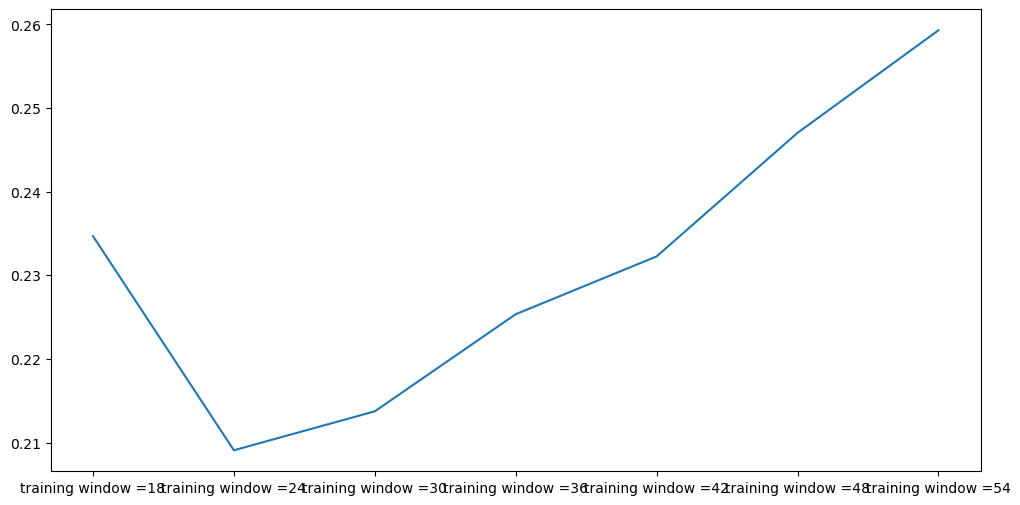

In [33]:
# Plot annualised returns for nearby specifications

stability_table['ann_ret'].plot(figsize = (12,6))

<Axes: xlabel='Date'>

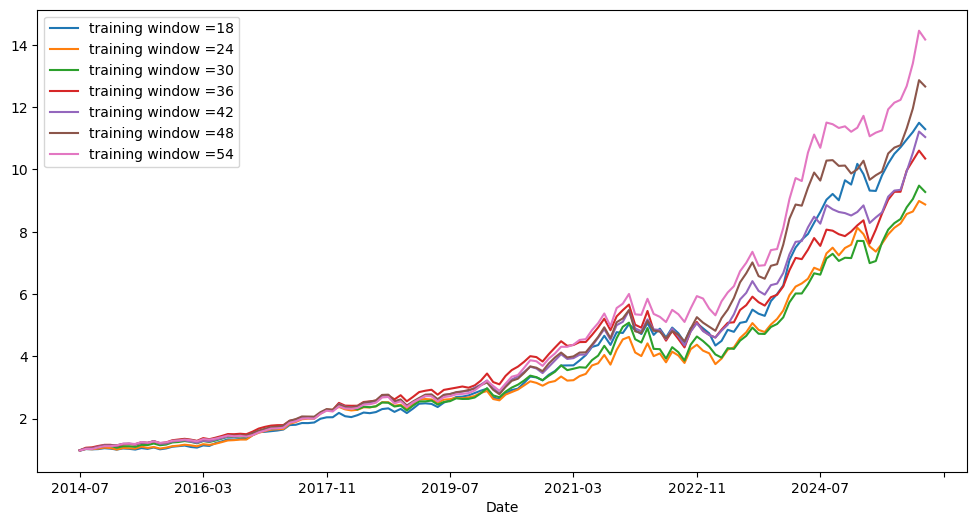

In [34]:
# Plot cumulative wealth

(1 + ret_df).cumprod().plot(figsize = (12,6))

### Model Dependence

In [35]:
# Compare MSR to EW

tear_sheet(results_all3.dropna(), rf=0.03, freq=12)

,ann_ret,ann_vol,max_dd,VaR 5,CVaR 5,sharpe
GMV_mod,0.157965,0.130311,-0.2335,0.060893,0.073266,0.966931
MSR_mod,0.251609,0.153443,-0.1703,0.060899,0.076161,1.356541
EW,0.169317,0.150408,-0.1972,0.063672,0.087485,0.921698


Based on raw returns, the modified Maximum Sharpe Ratio strategy ($MSR_{mod}$) substantially outperforms the Equal-Weighted (EW) benchmark portfolio. It delivers an annualized return of 25.16% compared to the EW portfolio's 16.93%, along with a significantly higher Sharpe ratio of 1.357 versus 0.922, and a lower maximum drawdown of -17.03% compared to -19.72%.

However, this comparison should be interpreted with caution. Higher returns do not necessarily imply a better strategy, as they may reflect exposure to common risk factors rather than unique sources of return. This issue is addressed in the next part where we perform risk adjustment.

In [43]:
# Joining Data

strategy_ret = pd.DataFrame({
    "MSR_mod": port_ret_msr_constrained,
    "EW":port_ret_ew,
}).dropna()

factor_ret = get_factor_ret()

# Cast the indices of both DataFrames to identical string formats
strategy_ret.index = strategy_ret.index.astype(str)
factor_ret.index = factor_ret.index.astype(str)


# Combine strategy and factor data using inner join
data = strategy_ret.join(factor_ret, how="inner")

data.head()

,MSR_mod,EW,Mkt-RF,SMB,HML,RF,Mom
2015-01,0.026438,-0.028433,-0.0310,-0.0059,-0.0345,0.0,0.0374
2015-02,0.051906,0.065363,0.0613,0.0061,-0.0179,0.0,-0.0310
2015-03,0.004489,-0.013973,-0.0111,0.0305,-0.0038,0.0,0.0270
2015-04,-0.015083,0.017799,0.0059,-0.0299,0.0180,0.0,-0.0727
2015-05,0.060868,0.018762,0.0137,0.0095,-0.0111,0.0,0.0568


In [44]:
# Custom function to compute alpha
def estimate_alpha(data, ret_col, factor_cols, rf_col="RF"):
    df = data[[ret_col] + factor_cols + [rf_col]].dropna()

    y = df[ret_col] - df[rf_col]
    X = sm.add_constant(df[factor_cols])

    model = sm.OLS(y, X).fit()

    alpha_m = model.params["const"]
    alpha_t = model.tvalues["const"]
    r2 = model.rsquared

    return {
        "alpha_monthly": alpha_m,
        "alpha_annualised": 12 * alpha_m,
        "t_alpha": alpha_t,
        "r2": r2
    }

In [47]:
# Perform regression
models = {
    "CAPM": ["Mkt-RF"],
    "FF3": ["Mkt-RF", "SMB", "HML"],
    "FF3+Mom": ["Mkt-RF", "SMB", "HML", "Mom"]
}
results = []

for strat_name in strategy_ret.columns:
    for model_name, factor_cols in models.items():
        res = estimate_alpha(
            data=data,
            ret_col=strat_name,
            factor_cols=factor_cols
        )
        results.append({
            "strategy": strat_name,
            "model": model_name,
            **res
        })

alpha_table = pd.DataFrame(results)
alpha_table

,strategy,model,alpha_monthly,alpha_annualised,t_alpha,r2
0,MSR_mod,CAPM,0.010685,0.128224,3.956160,0.548158
1,MSR_mod,FF3,0.008708,0.104495,3.791445,0.684526
2,MSR_mod,FF3+Mom,0.007386,0.088634,3.644546,0.759030
3,EW,CAPM,0.003023,0.036279,3.008257,0.936250
4,EW,FF3,0.002788,0.033458,3.290183,0.956234
5,EW,FF3+Mom,0.002874,0.034485,3.371132,0.956553


The factor regression results demonstrate that conclusions regarding portfolio outperformance depend heavily on the multi-factor benchmarking framework employed, as seen by the structural compression of alpha when risk dimensions expand. For the optimized $MSR_{mod}$ strategy, the monthly alpha remains highly resilient and statistically meaningful across all specifications, shifting from an annualized CAPM alpha of 12.82% ($t = 3.96$) to a Carhart four-factor alpha of 8.86% ($t = 3.64$). Because this abnormal return survives the integration of style and momentum factors, it confirms that the strategy's gains are not merely a reflection of unhedged systematic exposures, but rather genuine idiosyncratic alpha generated by the sector-constrained optimization process. Conversely, the naive Equal-Weighted (EW) portfolio exhibits exceptionally high $R^2$ values that climb to 0.957 under the four-factor model, indicating that 95.7% of its monthly return variance is fully captured by common risk factors. While the EW portfolio maintains a small, stable annualized alpha of around 3.45%, its high concentration of systematic variance confirms that its strong raw performance is primarily driven by passive exposure to broad market risk factors rather than distinct selection skill.

### Summary for Reliability Analysis

The reliability and robustness analysis confirms the empirical validity of the optimal modified Maximum Sharpe Ratio strategy ($MSR_{mod}$) through a strict multi-stage verification framework. By executing a chronological data split, a structural firewall was established between the parameter discovery phase (2010–2021) and the out-of-sample evaluation phase (2021–2025). The localized parameter winners—a 12-month momentum lookback and a 36-month covariance estimation window—demonstrated exceptional performance persistence when exposed to the unseen evaluation sample, generating an annualized return of 26.12%, a Sharpe ratio of 1.551, and a restricted maximum drawdown of -8.91%. A full-sample local stability check across a 18-to-54-month continuum produced smooth transitions in Sharpe ratios (1.096 to 1.406) rather than chaotic performance drops, confirming the absence of parameter fragility. Finally, asset pricing regressions under CAPM, Fama-French Three-Factor, and Carhart Four-Factor models revealed that while the Equal-Weighted baseline's returns were largely captured by broad systematic risk factors ($R^2 = 0.957$), the $MSR_{mod}$ strategy maintained a highly resilient, statistically significant annualized alpha of 8.86% ($t = 3.64$) under the full four-factor model. This persistent abnormal return provides robust confirmation that the sector-constrained optimization framework extracts true idiosyncratic economic value capable of surviving shifting macroeconomic regimes.

## Final Report

#### Summary of Findings
This empirical study evaluated the out-of-sample performance of three distinct portfolio construction frameworks applied to a screened universe of 50 large-cap US equities. The objective was to assess the efficacy of traditional optimization models against constrained alternatives and a naive benchmark. The baseline unconstrained models, specifically the Global Minimum Variance ($GMV_{sample}$) and Maximum Sharpe Ratio ($MSR_{sample}$) portfolios, were estimated using historical data from January 2010 to January 2015. Out-of-sample testing from January 2015 onward revealed that these unconstrained models developed severe structural concentrations. Over 80% of total portfolio capital was clustered into just three sectors, while multiple sectors received absolute zero allocations.

To address this extreme concentration, a modified framework was introduced, imposing a strict 25% maximum capital allocation limit per industry sector. This modification yielded significant performance improvements. The sector-constrained Maximum Sharpe Ratio strategy ($MSR_{mod}$) emerged as the dominant framework, achieving an annualized out-of-sample return of 25.16%, a maximum drawdown of -17.03%, and a superior Sharpe ratio of 1.357. The sector-constrained Global Minimum Variance strategy ($GMV_{mod}$) successfully achieved the lowest absolute volatility of the cohort at 13.03%. Both optimized strategies were evaluated against an Equal-Weighted (EW) benchmark, which delivered a 16.93% annualized return and a 0.922 Sharpe ratio.

#### Interpretation of Results
The empirical divergence between the baseline and modified portfolios highlights the fundamental fragility of unconstrained mean-variance optimization. Classical mathematical programming treats sample estimates of expected returns and covariance matrices as flawless parameters. Consequently, the optimization engines overfit to historical noise, generating economically implausible corner solutions that demand strict regularization.

The imposition of the 25% sector ceiling functioned as an efficient structural regularizer. By forcing the models to distribute capital away from historically dominant industries, the boundary condition successfully mitigated idiosyncratic sector risk. For the $MSR_{mod}$ portfolio, this forced diversification captured a broader equity risk premium, leading to superior risk-adjusted efficiency. For the $GMV_{mod}$ portfolio, the constraint imposed a slight optimization penalty by forcing capital away from the lowest-covariance assets into higher-beta growth sectors. However, this penalty is entirely justified from an institutional risk-management perspective, as it prevents catastrophic single-industry tail risk. Furthermore, outperforming the zero-estimation EW benchmark validates that the active operational complexity of the constrained framework adds genuine economic value beyond passive market exposure.

#### Reliability Assessment
To ensure statistical validity and eliminate data-mining bias, the empirical framework evaluated the $MSR_{mod}$ strategy across three rigorous dimensions: validation, robustness, and model risk. The validation phase employed a strict chronological data partition that established a structural firewall, separating parameter discovery (2010–2021) from the rolling out-of-sample evaluation (2021–2025). The selected 36-month training window demonstrated exceptional performance persistence when applied to this unseen evaluation sample, confirming the strategy's predictive value and the complete absence of look-ahead bias.

Building on this, the robustness of the strategy was tested through a full-sample local stability check that varied the lookback horizon from 18 to 54 months. This check yielded smooth, continuous transitions in Sharpe ratios ranging from 1.096 to 1.406. The absolute absence of chaotic performance degradation or sharp metric collapses across these parameter variations confirms that the strategy is structurally sound and not reliant on a fragile, overfitted parameter configuration.

Finally, to address the model risk that apparent outperformance stems from unhedged exposure to systematic equity risk factors rather than active management skill, the portfolio's excess returns were subjected to multi-factor time-series regressions. While the baseline EW portfolio's performance was heavily absorbed by common risk indices, reaching an $R^2$ of 0.957, the $MSR_{mod}$ strategy maintained a highly resilient, statistically significant annualized alpha of 8.86% ($t = 3.64$) under the full Carhart four-factor architecture. This confirms that the abnormal returns survive adjustments for market, size, value, and momentum risk, validating the true idiosyncratic value of the sector constraints.

#### Limitations of the Analysis
Despite the robust statistical findings, several structural limitations must be acknowledged. First, the analysis relies on a static historical asset universe comprising 50 screened equities. This methodology inherently introduces survivorship bias, as companies that experienced bankruptcy, severe distress, or delisting prior to the end of the sample period were likely excluded from the dataset.

Second, the backtesting environment assumes entirely frictionless execution. Dynamic mathematical optimization frameworks require continuous, high-turnover weight rebalancing. In a live institutional trading environment, this frequency of adjustment generates substantial transaction costs, taxation, and bid-ask slippage. These market frictions would naturally compress the gross realized returns presented in the simulation.

Lastly, covariance matrices are notoriously sensitive to estimation error and are fundamentally backward-looking. The rolling-window optimization model implicitly assumes that historical asset correlations and volatility distributions will remain stationary in the short term. While the sector constraints heavily mitigate the impact of estimation noise, the foundational assumption of stationary covariance may fail during sudden, unprecedented macroeconomic shocks or global liquidity crises, potentially leading to structural drawdowns that exceed historical estimates.